In [1]:
import yaml as yml
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from turbo_colormap import turbo_colormap_data
import hcipy as hci
import sleec_optics as slo
import sleec_alter as sla
import sleec_input as sli

turbo = ListedColormap(turbo_colormap_data)

In [2]:
corngrph1, pars = sli.import_pars(verbose=False)

In [3]:
aperture = ( hci.circular_aperture(corngrph1.pupil_diameter)
                                    (corngrph1.pupil_field.grid) )

input_field= (
        hci.Field(np.ones_like(corngrph1.pupil_field.grid.x)
                  , corngrph1.pupil_field.grid)*aperture
                 )
input_wf = hci.Wavefront(input_field, corngrph1.wvl)

In [4]:
output1 = corngrph1(input_wf)

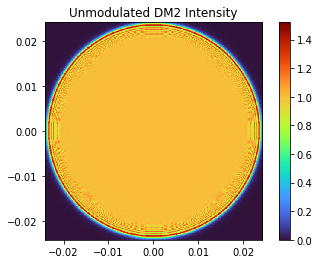

In [5]:
dm2_wf1 = output1['dm2']
hci.imshow_field(dm2_wf1.intensity, cmap=turbo)
plt.title('Unmodulated DM2 Intensity')
plt.colorbar()

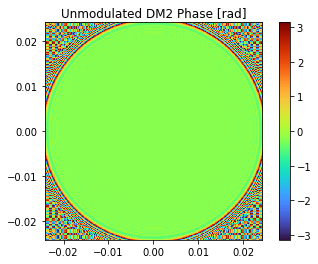

In [6]:
hci.imshow_field(dm2_wf1.phase, cmap=turbo)
plt.title('Unmodulated DM2 Phase [rad]')
plt.colorbar()

In [7]:
grid = corngrph1.pupil_field.grid
D = corngrph1.pupil_diameter
wvl = corngrph1.wvl
talbot_freq = 1.0/np.sqrt(wvl*corngrph1.dm_seprtn/2)

In [8]:
freq = talbot_freq/2.0  # z_Talbot/4
# freq = talbot_freq/np.sqrt(2.0)  # z_Talbot/2
# freq = talbot_freq # z_Talbot 
ampl = wvl/60

In [9]:
print('frequency = {} cyc/D'.format(freq*D))
print('amplitude = {}'.format(ampl))

frequency = 44.95611895592131 cyc/D
amplitude = 9.5e-09


In [10]:
# r = grid.as_('polar').r
# apodz = np.cos(2*np.pi*0.5*r/D)
# apodz = np.where(r>D/2, 0, apodz)
# surface = hci.Field(ampl*np.sin(2*np.pi*freq*grid.x)
#                     *apodz
#                     , grid)
surface = hci.Field(ampl*np.sin(2*np.pi*freq*grid.x)
                    , grid)

In [11]:
corngrph2 = sla.update_dm1_surfc(surface, corngrph1)

In [12]:
output2 = corngrph2(input_wf)

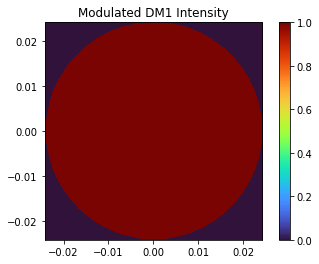

In [13]:
dm1_wf2 = output2['dm1']
hci.imshow_field(dm1_wf2.intensity, cmap=turbo)
plt.title('Modulated DM1 Intensity')
plt.colorbar()

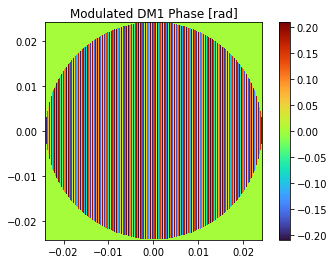

In [14]:
hci.imshow_field(dm1_wf2.phase, cmap=turbo)
plt.title('Modulated DM1 Phase [rad]')
plt.colorbar()

Text(0.5, 1.0, 'Cross-Section of Modulated DM1 Phase [rad]')

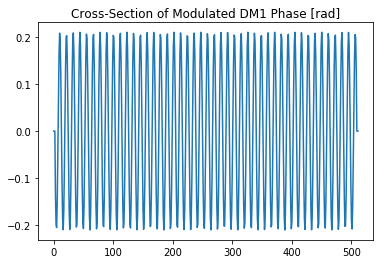

In [15]:
plt.plot(dm1_wf2.phase.reshape(512, 512)[256, :])
plt.title('Cross-Section of Modulated DM1 Phase [rad]')

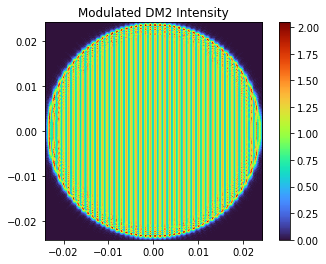

In [16]:
dm2_wf2 = output2['dm2']
hci.imshow_field(dm2_wf2.intensity, cmap=turbo)
plt.title('Modulated DM2 Intensity')
plt.colorbar()

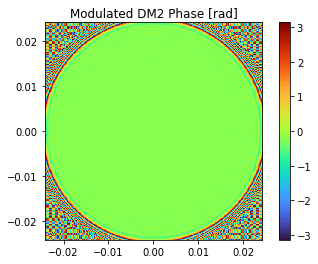

In [17]:
hci.imshow_field(dm2_wf2.phase, cmap=turbo)
plt.title('Modulated DM2 Phase [rad]')
plt.colorbar()

Text(0.5, 1.0, 'Cross-Section of Modulated DM2 Intensity')

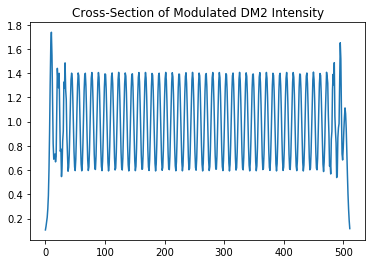

In [18]:
plt.plot(dm2_wf2.intensity.reshape(512, 512)[256, :])
plt.title('Cross-Section of Modulated DM2 Intensity')

Text(0.5, 1.0, 'Cross-Section of Modulated DM2 Phase [rad]')

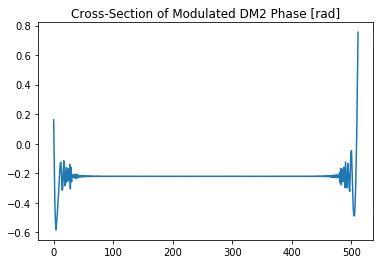

In [19]:
plt.plot(dm2_wf2.phase.reshape(512, 512)[256, :])
plt.title('Cross-Section of Modulated DM2 Phase [rad]')

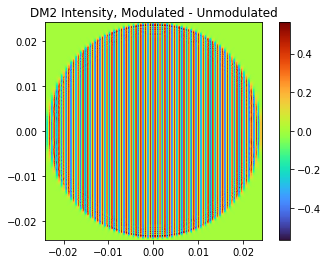

In [20]:
hci.imshow_field(dm2_wf2.intensity-dm2_wf1.intensity, cmap=turbo)
plt.title('DM2 Intensity, Modulated - Unmodulated')
plt.colorbar()

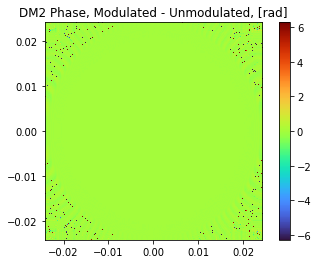

In [21]:
hci.imshow_field(dm2_wf2.phase-dm2_wf1.phase, cmap=turbo)
plt.title('DM2 Phase, Modulated - Unmodulated, [rad]')
plt.colorbar()

Text(0.5, 1.0, 'Cross-Section of Modulated DM2 Intensity Diff')

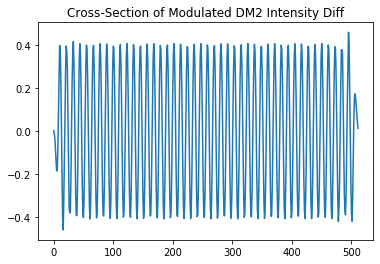

In [22]:
plt.plot((dm2_wf2.intensity-dm2_wf1.intensity).reshape(512, 512)[256, :])
plt.title('Cross-Section of Modulated DM2 Intensity Diff')

Text(0.5, 1.0, 'Cross-Section of Modulated DM2 Phase Diff [rad]')

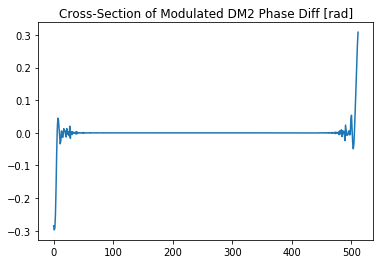

In [27]:
plt.plot((dm2_wf2.phase-dm2_wf1.phase).reshape(512, 512)[256, :])
plt.title('Cross-Section of Modulated DM2 Phase Diff [rad]')

In [28]:
m = [0]
n_min = 23
n_max = 23
bc = 'dirichlet'
coefs = (wvl/60)*np.ones(len(m)*(n_max+1-n_min))
print('Coefficients = {}'.format(coefs))
dm = 'dm1'
file_exists = False
if dm == 'dm1':
    filename = '../../sleec_out/disk_harmonic_dm1.pkl'
if dm == 'dm2':
    filename = '../../sleec_out/disk_harmonic_dm2.pkl'
if dm == 'dm2dm1':
    filename = '../../sleec_out/disk_harmonic_dm2dm1.pkl'
corngrph3 = sla.dm_disk_harmonic(coefs=coefs, corngrph=corngrph1, dm=dm
                            , file_exists=file_exists, filename=filename
                            , m=m, n_min=n_min, n_max=n_max, bc=bc)
output3 = corngrph3(input_wf)
dm2_wf3 = output3['dm2']

Coefficients = [9.5e-09]
[(0, 23)]


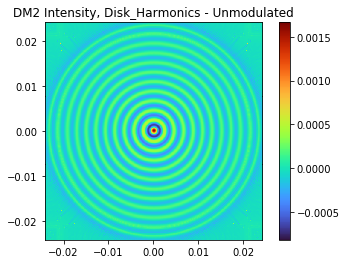

In [31]:
# hci.imshow_field(dm2_wf3.intensity-dm2_wf1.intensity, cmap=turbo)
hci.imshow_field(np.log10(dm2_wf3.intensity/dm2_wf1.intensity), cmap=turbo)
plt.title('DM2 Intensity, Disk_Harmonics - Unmodulated')
plt.colorbar()

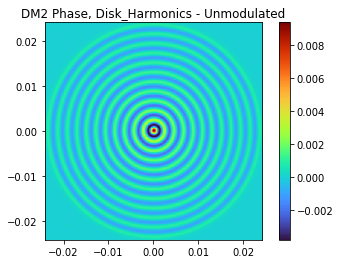

In [30]:
hci.imshow_field(dm2_wf3.phase-dm2_wf1.phase, cmap=turbo)
plt.title('DM2 Phase, Disk_Harmonics - Unmodulated')
plt.colorbar()